# Initial SUMO Scenario Pipeline

Run a standalone pipeline that translates traffic demand and directional imbalance into SUMO inputs, compares fixed-time and actuated signals, and evaluates delay, queue length, and travel time. This notebook calls `initial_simulation`; the simulation logic also runs from the command line.

## Contents
1. [Experiment Setup](#1.-Experiment-Setup)
2. [Demand Pilot](#2.-Demand-Pilot)
3. [Scenario Inputs](#3.-Scenario-Inputs)
4. [Run Pipeline](#4.-Run-Pipeline)
5. [Execution Checks](#5.-Execution-Checks)
6. [Controller Comparison](#6.-Controller-Comparison)
7. [Initial Scenario Analysis](#7.-Initial-Scenario-Analysis)
8. [Inspect a Scenario](#8.-Inspect-a-Scenario)

Run cells in order. Default levels are synthetic choices, not Compass-calibrated estimates. Successful matching runs are cached. Figures are saved in the full experiment's `figures/` folder. See [the pipeline README](../initial_simulation/README.md) for execution and design details.


## 1. Experiment Setup

Check the two feature levels, fixed geometry, signal settings, and timing before running. The output names identify one configuration/code/SUMO version; choose new names after changing any of them.

Total requested demand is `Q = q_N + q_E + q_S + q_W`. Directional imbalance is `D = (q_N + q_S - q_E - q_W) / Q`. Set `q_N = q_S = Q(1+D)/4` and `q_E = q_W = Q(1-D)/4`. Negative D favors EW; positive D favors NS.


In [1]:
from pathlib import Path
import json, shlex, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'initial_simulation' / 'configs' / 'default.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the repository root or notebooks/.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from initial_simulation import (load_config, prepare_experiment, run_pilot,
                                run_experiment, load_results, gui_command)
from initial_simulation.plotting import (METRICS, plot_demand, plot_metric_comparison,
                                        plot_queues, controller_differences)

CONFIG_PATH = ROOT / 'initial_simulation' / 'configs' / 'default.json'
PILOT_NAME = 'pilot'
EXPERIMENT_NAME = 'baseline'
PILOT_DIR = ROOT / 'results' / 'initial_simulation' / PILOT_NAME
EXPERIMENT_DIR = ROOT / 'results' / 'initial_simulation' / EXPERIMENT_NAME
config = load_config(CONFIG_PATH)
pd.set_option('display.max_columns', 20)
display(pd.DataFrame([
    ['Total demand Q (veh/h)', list(config.demand_vph)],
    ['Directional imbalance D', list(config.directional_imbalance)],
    ['Turn shares: left / through / right', [config.left_share, 1-config.left_share-config.right_share, config.right_share]],
    ['Geometry', f'One inbound/outbound lane per arm; {config.arm_length_m:g} m outer-node distance'],
    ['Speed limit (km/h)', config.speed_mps * 3.6],
    ['Fixed green / yellow / all-red (s)', [config.fixed_green_s, config.yellow_s, config.all_red_s]],
    ['Actuated minimum / maximum green (s)', [config.min_green_s, config.max_green_s]],
    ['Warm-up / evaluation / drain (s)', [config.warmup_s, config.evaluation_s, config.drain_s]],
    ['Primary metrics', 'Average delay, average queue length, average travel time'],
], columns=['Setting', 'Value']))


,Setting,Value
0,Total demand Q (veh/h),"[600, 1200, 1800]"
1,Directional imbalance D,"[-0.5, 0.0, 0.5]"
2,Turn shares: left / through / right,"[0.1, 0.8, 0.1]"
3,Geometry,One inbound/outbound lane per arm; 200 m outer...
4,Speed limit (km/h),50.0
5,Fixed green / yellow / all-red (s),"[20, 3, 1]"
6,Actuated minimum / maximum green (s),"[10, 40]"
7,Warm-up / evaluation / drain (s),"[300, 1800, 900]"
8,Primary metrics,"Average delay, average queue length, average t..."


## 2. Demand Pilot

Review lighter and congested conditions before accepting the default 600/1200/1800 veh/h levels. The pilot runs all nine scenarios with the fixed-time controller, using 120 s warm-up, 600 s demand, and 300 s drain. It does not choose levels based on controller differences or automatically alter the full experiment.

Compare average queue size, queues in the first and last thirds of the demand window, and remaining/uninserted vehicles. A pending vehicle at the cutoff is incomplete demand, not a simulation error. Values are synthetic experiment settings; update the configuration and output names if different levels are needed.


Cached s01 / fixed
Cached s02 / fixed
Cached s03 / fixed
Cached s04 / fixed
Cached s05 / fixed
Cached s06 / fixed
Cached s07 / fixed
Cached s08 / fixed
Cached s09 / fixed


,scenario_id,demand_vph,imbalance,average_queue_vehicles,queue_first_third,queue_last_third,completion_rate,unfinished_vehicles,uninserted_vehicles,valid_run
0,s01,600,-0.5,5.202,5.290,5.130,1.000,0,0,True
1,s02,600,0.0,4.683,4.625,4.660,1.000,0,0,True
2,s03,600,0.5,5.183,5.265,5.090,1.000,0,0,True
3,s04,1200,-0.5,19.095,15.565,22.520,1.000,0,0,True
4,s05,1200,0.0,9.958,10.410,9.685,1.000,0,0,True
5,s06,1200,0.5,17.895,14.230,21.705,1.000,0,0,True
6,s07,1800,-0.5,40.725,37.770,41.810,0.845,45,2,True
7,s08,1800,0.0,32.307,25.170,39.565,1.000,0,0,True
8,s09,1800,0.5,40.422,36.345,42.215,0.832,49,2,True


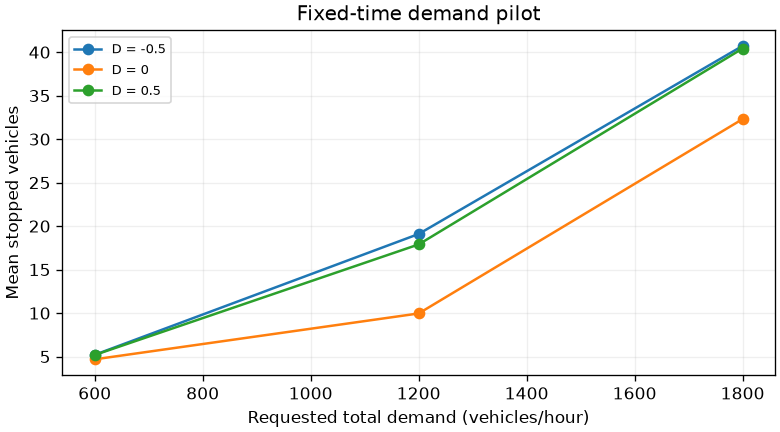

In [2]:
pilot_dir = run_pilot(config, PILOT_DIR)
pilot = load_results(pilot_dir)['summary']
display(pilot[['scenario_id', 'demand_vph', 'imbalance', 'average_queue_vehicles',
               'queue_first_third', 'queue_last_third', 'completion_rate',
               'unfinished_vehicles', 'uninserted_vehicles', 'valid_run']].round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.6), constrained_layout=True)
for imbalance, frame in pilot.groupby('imbalance'):
    frame = frame.sort_values('demand_vph')
    ax.plot(frame['demand_vph'], frame['average_queue_vehicles'], marker='o', label=f'D = {imbalance:g}')
ax.set(xlabel='Requested total demand (vehicles/hour)', ylabel='Mean stopped vehicles',
       title='Fixed-time demand pilot')
ax.legend(fontsize=8)
ax.grid(alpha=.2)
plt.show()


## 3. Scenario Inputs

Check the mapping from Q/D to approach flows and compare requested features with effective finite-window counts. SUMO movement flows start at their `begin` time, so fractional expected vehicle counts are rounded by the departure schedule. Effective Q, D, and turning share expose this small discretization effect.

The same demand file is shared by both controllers. The input flow rates, not realized throughput, define the scenario features.


Example movement flows: s05


,scenario_id,demand_vph,imbalance,direction,q_N_vph,q_E_vph,q_S_vph,q_W_vph,scheduled_eval_vehicles,effective_demand_vph,effective_imbalance,effective_turning_share
0,s01,600,-0.5,EW-heavy,75.0,225.0,75.0,225.0,304,608.0,-0.5000,0.2105
1,s02,600,0.0,balanced,150.0,150.0,150.0,150.0,304,608.0,0.0000,0.2105
2,s03,600,0.5,NS-heavy,225.0,75.0,225.0,75.0,304,608.0,0.5000,0.2105
3,s04,1200,-0.5,EW-heavy,150.0,450.0,150.0,450.0,604,1208.0,-0.4967,0.2053
4,s05,1200,0.0,balanced,300.0,300.0,300.0,300.0,600,1200.0,0.0000,0.2000
5,s06,1200,0.5,NS-heavy,450.0,150.0,450.0,150.0,604,1208.0,0.4967,0.2053
6,s07,1800,-0.5,EW-heavy,225.0,675.0,225.0,675.0,904,1808.0,-0.4956,0.2035
7,s08,1800,0.0,balanced,450.0,450.0,450.0,450.0,904,1808.0,0.0000,0.2035
8,s09,1800,0.5,NS-heavy,675.0,225.0,675.0,225.0,904,1808.0,0.4956,0.2035


,flow_id,cohort,approach,movement,rate_vph,begin_s,end_s,scheduled_vehicles
0,eval_N_L,eval,N,L,30.0,300,2100,15
1,eval_N_T,eval,N,T,240.0,300,2100,120
2,eval_N_R,eval,N,R,30.0,300,2100,15
3,eval_E_L,eval,E,L,30.0,300,2100,15
4,eval_E_T,eval,E,T,240.0,300,2100,120
5,eval_E_R,eval,E,R,30.0,300,2100,15
6,eval_S_L,eval,S,L,30.0,300,2100,15
7,eval_S_T,eval,S,T,240.0,300,2100,120
8,eval_S_R,eval,S,R,30.0,300,2100,15
9,eval_W_L,eval,W,L,30.0,300,2100,15


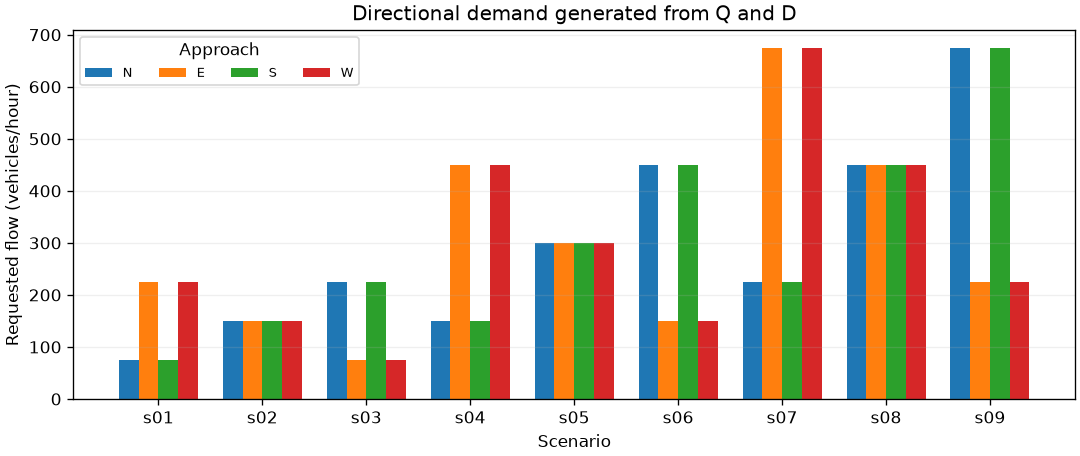

In [3]:
prepare_experiment(config, EXPERIMENT_DIR)
scenarios = pd.read_csv(EXPERIMENT_DIR / 'scenarios.csv')
display(scenarios.round(4))
input_scenario = scenarios.iloc[4]['scenario_id'] if len(scenarios) > 4 else scenarios.iloc[0]['scenario_id']
flows = pd.read_csv(EXPERIMENT_DIR / 'scenarios' / input_scenario / 'flows.csv')
print('Example movement flows:', input_scenario)
display(flows.loc[flows['cohort'].eq('eval')].reset_index(drop=True))
fig = plot_demand(scenarios)
plt.show()


## 4. Run Pipeline

Run the nine scenarios with both controllers: 18 deterministic simulations. Completed runs with unchanged inputs and output checksums are reused; this cell does not repeat SUMO merely to redraw figures.

The network geometry is common. Only the signal program differs. Each run uses 5 min warm-up, 30 min demand, and up to a 15 min fixed drain. No new vehicles are scheduled during the drain.


In [4]:
experiment_dir = run_experiment(config, EXPERIMENT_DIR)
results = load_results(experiment_dir)
summary = results['summary']
queues = results['queues']
manifest = json.loads((experiment_dir / 'experiment.json').read_text())
print('SUMO:', manifest['sumo_version'])
print('Experiment:', experiment_dir)
print('Scenario/controller runs:', len(summary))


Cached s01 / fixed
Cached s01 / actuated
Cached s02 / fixed
Cached s02 / actuated
Cached s03 / fixed
Cached s03 / actuated
Cached s04 / fixed
Cached s04 / actuated
Cached s05 / fixed
Cached s05 / actuated
Cached s06 / fixed
Cached s06 / actuated
Cached s07 / fixed
Cached s07 / actuated
Cached s08 / fixed
Cached s08 / actuated
Cached s09 / fixed
Cached s09 / actuated
SUMO: Eclipse SUMO sumo 1.28.0
Experiment: /Users/jiyoon/Desktop/git/informative-scenario-mining/results/initial_simulation/baseline
Scenario/controller runs: 18


## 5. Execution Checks

Check that each requested evaluation vehicle is completed, still running, waiting for insertion, or abnormally removed. Inspect collisions, teleports, and detector/traffic warnings before comparing performance.

An incomplete cohort is not an invalid run: high demand may exceed service or insertion capacity. Keep its completion information visible. Mean delay and travel time use completed vehicles only; they must not be interpreted as full-cohort means when vehicles remain.


In [5]:
check_columns = ['scenario_id', 'controller', 'planned_vehicles', 'completed_vehicles',
                 'unfinished_vehicles', 'uninserted_vehicles', 'removed_vehicles',
                 'completion_rate', 'collisions', 'teleports', 'valid_run', 'complete_cohort']
display(summary[check_columns].round(3))
assert len(summary) == len(scenarios) * 2, 'Some scenario/controller results are missing.'
assert summary['valid_run'].all(), 'Inspect invalid runs and their logs before interpreting metrics.'
assert (summary['planned_vehicles'] == summary[['completed_vehicles', 'unfinished_vehicles',
                                               'uninserted_vehicles', 'removed_vehicles']].sum(axis=1)).all()
print('Execution integrity checks passed. Incomplete cohorts:', int((~summary['complete_cohort']).sum()))


Execution integrity checks passed. Incomplete cohorts: 2


,scenario_id,controller,planned_vehicles,completed_vehicles,unfinished_vehicles,uninserted_vehicles,removed_vehicles,completion_rate,collisions,teleports,valid_run,complete_cohort
0,s01,actuated,304,304,0,0,0,1.000,0,0,True,True
1,s01,fixed,304,304,0,0,0,1.000,0,0,True,True
2,s02,actuated,304,304,0,0,0,1.000,0,0,True,True
3,s02,fixed,304,304,0,0,0,1.000,0,0,True,True
4,s03,actuated,304,304,0,0,0,1.000,0,0,True,True
5,s03,fixed,304,304,0,0,0,1.000,0,0,True,True
6,s04,actuated,604,604,0,0,0,1.000,0,0,True,True
7,s04,fixed,604,604,0,0,0,1.000,0,0,True,True
8,s05,actuated,600,600,0,0,0,1.000,0,0,True,True
9,s05,fixed,600,600,0,0,0,1.000,0,0,True,True


## 6. Controller Comparison

Compare three primary metrics across the Q/D grid. Both controller panels use the same color scale for each metric. An asterisk marks an incomplete evaluation cohort.

- **Average delay:** mean SUMO `timeLoss` over completed evaluation vehicles, in seconds/vehicle. This is not a separately computed HCM control delay and excludes pre-insertion waiting.
- **Average queue length:** time mean of the summed stopped-vehicle counts on the four inbound lanes, in vehicles. The threshold is speed <0.1 m/s. Directional means are also retained; the total is their sum.
- **Average travel time:** mean `duration` over completed evaluation vehicles, from actual upstream insertion to the downstream end of the outbound route, in seconds/vehicle.

Vehicle means include evaluation vehicles that complete during the drain. Queue means use only the common evaluation window and include all vehicles physically present, including warm-up remnants. No incomplete vehicle is assigned zero delay or travel time.


,scenario_id,controller,demand_vph,imbalance,average_delay_s,average_queue_vehicles,average_travel_time_s,completion_rate
0,s01,actuated,600,-0.5,21.948,3.084,51.089,1.000
1,s01,fixed,600,-0.5,36.295,5.467,65.434,1.000
2,s02,actuated,600,0.0,18.667,2.632,47.809,1.000
3,s02,fixed,600,0.0,32.201,4.884,61.322,1.000
4,s03,actuated,600,0.5,22.826,3.217,51.967,1.000
5,s03,fixed,600,0.5,33.636,5.057,62.760,1.000
6,s04,actuated,1200,-0.5,27.865,7.993,56.974,1.000
7,s04,fixed,1200,-0.5,108.918,31.201,138.005,1.000
8,s05,actuated,1200,0.0,27.431,7.783,56.537,1.000
9,s05,fixed,1200,0.0,35.938,10.687,65.067,1.000


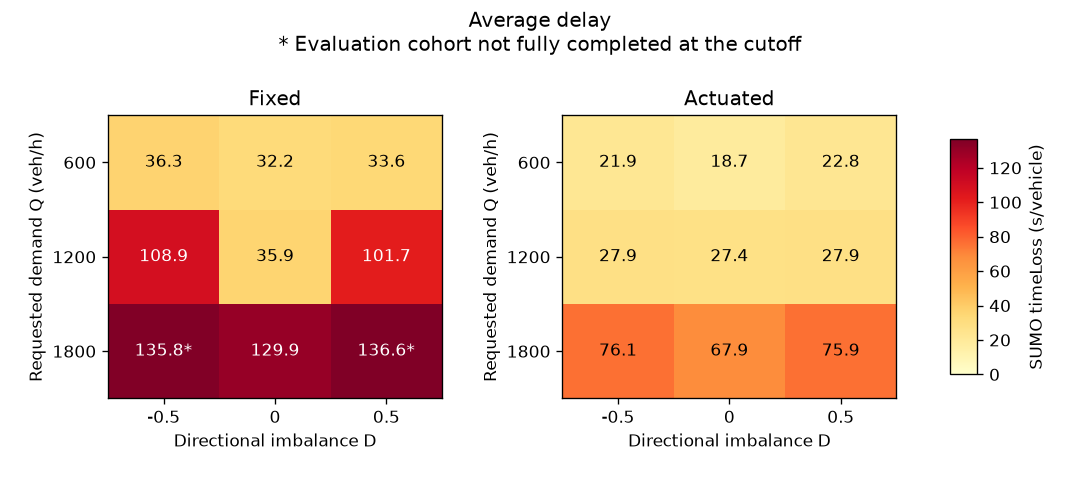

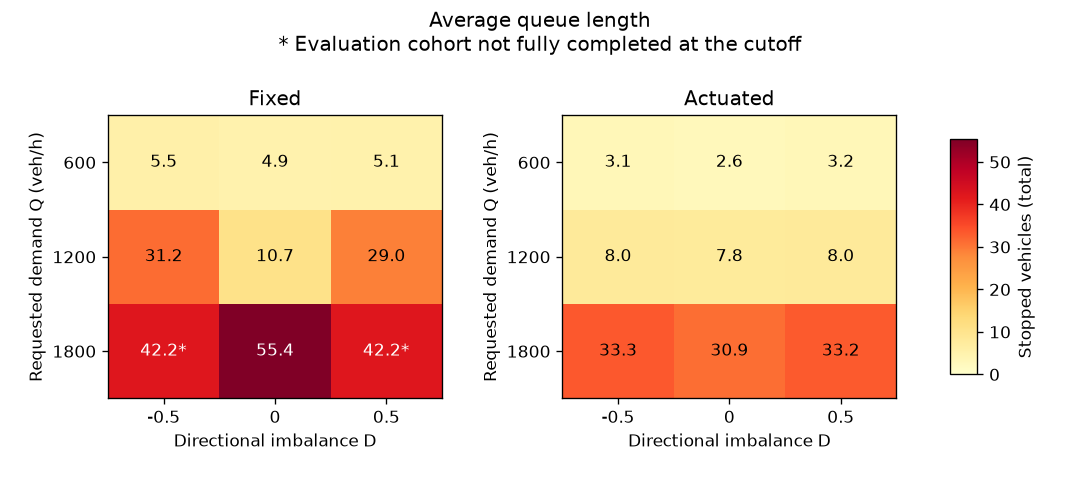

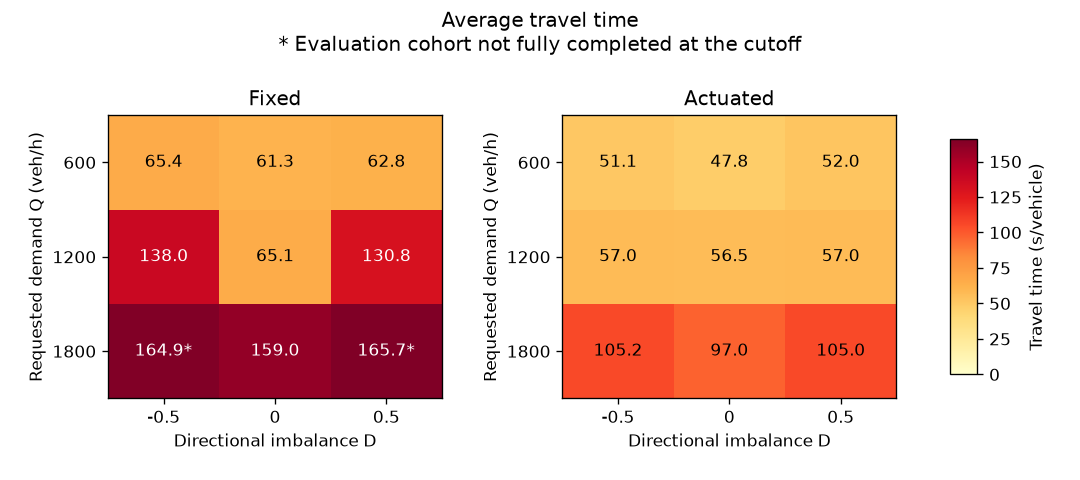

In [6]:
metric_columns = ['scenario_id', 'controller', 'demand_vph', 'imbalance',
                  *METRICS, 'completion_rate']
display(summary[metric_columns].round(3))
FIGURE_DIR = experiment_dir / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)
for metric in METRICS:
    fig = plot_metric_comparison(summary, metric)
    fig.savefig(FIGURE_DIR / f'{metric}.png', dpi=180, facecolor='white')
    plt.show()


## 7. Initial Scenario Analysis

Inspect fixed-minus-actuated differences: positive values favor the actuated controller for these lower-is-better metrics. Delay and travel-time differences are withheld unless both runs have valid, complete evaluation cohorts. Queue differences use a common time window and remain available for valid incomplete runs.

Use this table to select examples for investigation. It is a small exhaustive grid comparison, not an optimized scenario search or a validated informativeness score. Regular deterministic arrivals do not support statistical confidence claims from seed repetition.


In [7]:
differences = controller_differences(summary)
display(differences.round(3))
differences.to_csv(experiment_dir / 'controller_differences.csv', index=False)
completed_pairs = differences.loc[differences['complete_valid_pair']].copy()
completed_pairs['absolute_delay_difference_s'] = completed_pairs['fixed_minus_actuated_average_delay_s'].abs()
print('Largest delay differences among valid, complete pairs:')
display(completed_pairs.sort_values('absolute_delay_difference_s', ascending=False).head(3).round(3))


Largest delay differences among valid, complete pairs:


,scenario_id,demand_vph,imbalance,complete_valid_pair,fixed_completion_rate,actuated_completion_rate,fixed_minus_actuated_average_delay_s,fixed_minus_actuated_average_queue_vehicles,fixed_minus_actuated_average_travel_time_s
0,s01,600,-0.5,True,1.000,1.0,14.346,2.382,14.345
1,s02,600,0.0,True,1.000,1.0,13.534,2.252,13.513
2,s03,600,0.5,True,1.000,1.0,10.810,1.841,10.793
3,s04,1200,-0.5,True,1.000,1.0,81.053,23.208,81.031
4,s05,1200,0.0,True,1.000,1.0,8.507,2.904,8.530
5,s06,1200,0.5,True,1.000,1.0,73.828,21.046,73.801
6,s07,1800,-0.5,False,0.893,1.0,NaN,8.870,NaN
7,s08,1800,0.0,True,1.000,1.0,62.015,24.431,61.989
8,s09,1800,0.5,False,0.892,1.0,NaN,9.007,NaN


,scenario_id,demand_vph,imbalance,complete_valid_pair,fixed_completion_rate,actuated_completion_rate,fixed_minus_actuated_average_delay_s,fixed_minus_actuated_average_queue_vehicles,fixed_minus_actuated_average_travel_time_s,absolute_delay_difference_s
3,s04,1200,-0.5,True,1.0,1.0,81.053,23.208,81.031,81.053
5,s06,1200,0.5,True,1.0,1.0,73.828,21.046,73.801,73.828
7,s08,1800,0.0,True,1.0,1.0,62.015,24.431,61.989,62.015


## 8. Inspect a Scenario

Choose a scenario to compare its four approach queues at every evaluation timestep. Read the completion information alongside the traces, especially for high or imbalanced demand. The lines are not smoothed.

GUI commands replay the same prepared inputs without writing evaluation outputs. They are printed for optional use; this cell does not launch a GUI automatically.


fixed: /Library/Frameworks/EclipseSUMO.framework/Versions/1.28.0/EclipseSUMO/bin/sumo-gui -c /Users/jiyoon/Desktop/git/informative-scenario-mining/results/initial_simulation/baseline/runs/s08/fixed/replay.sumocfg --start
actuated: /Library/Frameworks/EclipseSUMO.framework/Versions/1.28.0/EclipseSUMO/bin/sumo-gui -c /Users/jiyoon/Desktop/git/informative-scenario-mining/results/initial_simulation/baseline/runs/s08/actuated/replay.sumocfg --start


,scenario_id,demand_vph,imbalance,direction,q_N_vph,q_E_vph,q_S_vph,q_W_vph,scheduled_eval_vehicles,effective_demand_vph,effective_imbalance,effective_turning_share
7,s08,1800,0.0,balanced,450.0,450.0,450.0,450.0,904,1808.0,0.0,0.204


,controller,average_delay_s,average_queue_vehicles,average_travel_time_s,completion_rate,unfinished_vehicles,uninserted_vehicles
14,actuated,67.887,30.923,96.985,1.0,0,0
15,fixed,129.902,55.353,158.973,1.0,0,0


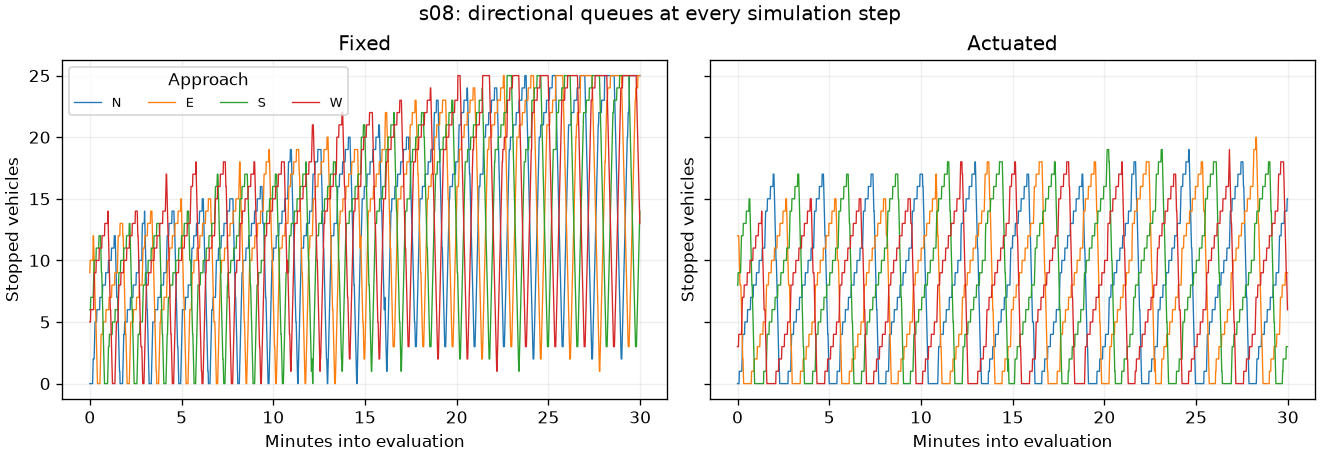

In [8]:
SELECTED_SCENARIO = 's08'
display(scenarios.loc[scenarios['scenario_id'].eq(SELECTED_SCENARIO)].round(3))
display(summary.loc[summary['scenario_id'].eq(SELECTED_SCENARIO),
                    ['controller', *METRICS, 'completion_rate', 'unfinished_vehicles', 'uninserted_vehicles']].round(3))
fig = plot_queues(queues, SELECTED_SCENARIO, config.warmup_s)
fig.savefig(FIGURE_DIR / f'{SELECTED_SCENARIO}_queues.png', dpi=180, facecolor='white')
plt.show()
for controller in ['fixed', 'actuated']:
    print(controller + ': ' + shlex.join(gui_command(experiment_dir, SELECTED_SCENARIO, controller)))
